# EDA — Telco Customer Churn (datos limpios)

Exploración rápida de `data/processed/telco_clean.csv` generado por `src/etl.py`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/processed/telco_clean.csv")
df.shape

(7043, 21)

## Overview general

In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304,0.265370
std,0.368612,24.559481,30.090047,2266.794470,0.441561
min,0.000000,0.000000,18.250000,0.000000,0.000000
25%,0.000000,9.000000,35.500000,398.550000,0.000000
50%,0.000000,29.000000,70.350000,1394.550000,0.000000
75%,0.000000,55.000000,89.850000,3786.600000,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000


## Nulos y duplicados (sanity check post-ETL)

In [5]:
print("Nulos por columna:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nFilas duplicadas:", df.duplicated().sum())
print("customerID duplicados:", df["customerID"].duplicated().sum())

Nulos por columna:
Series([], dtype: int64)

Filas duplicadas: 0
customerID duplicados: 0


## Variable objetivo: Churn

Tasa de churn global: 26.54%


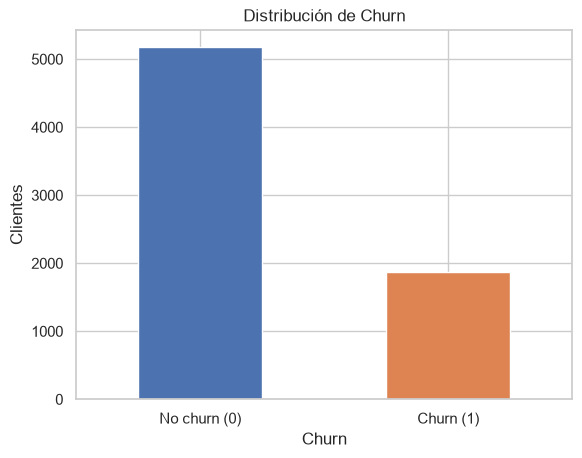

In [6]:
churn_rate = df["Churn"].mean()
print(f"Tasa de churn global: {churn_rate:.2%}")

ax = df["Churn"].value_counts().sort_index().plot(kind="bar", color=["#4C72B0", "#DD8452"])
ax.set_xticklabels(["No churn (0)", "Churn (1)"], rotation=0)
ax.set_ylabel("Clientes")
ax.set_title("Distribución de Churn")
plt.show()

## Distribución de variables numéricas

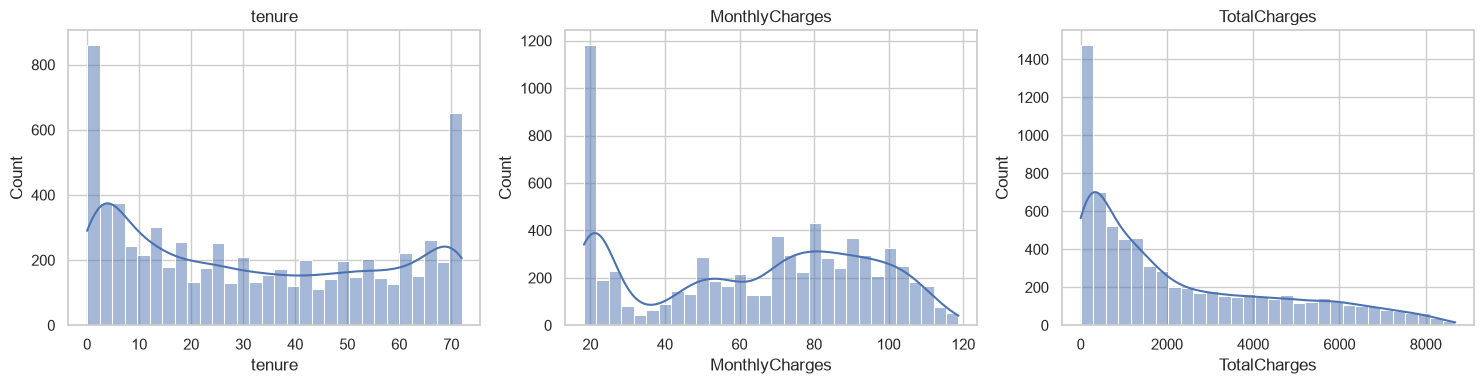

In [7]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_cols):
    sns.histplot(df[col], bins=30, ax=ax, kde=True)
    ax.set_title(col)
plt.tight_layout()
plt.show()

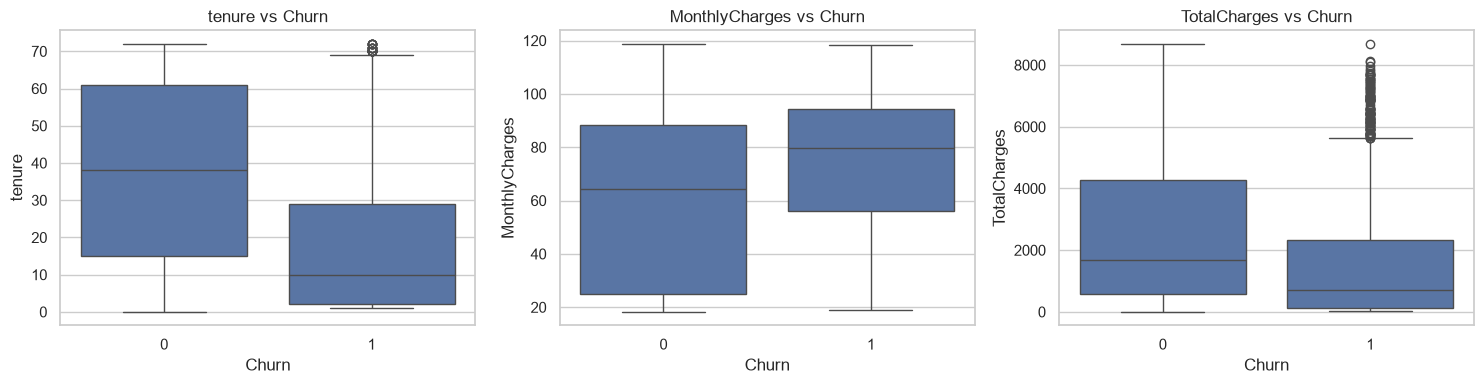

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=df, x="Churn", y=col, ax=ax)
    ax.set_title(f"{col} vs Churn")
plt.tight_layout()
plt.show()

## Variables categóricas vs Churn

In [9]:
categorical_cols = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod",
]

churn_by_cat = {
    col: df.groupby(col)["Churn"].mean().sort_values(ascending=False)
    for col in categorical_cols
}
churn_by_cat["Contract"]

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64

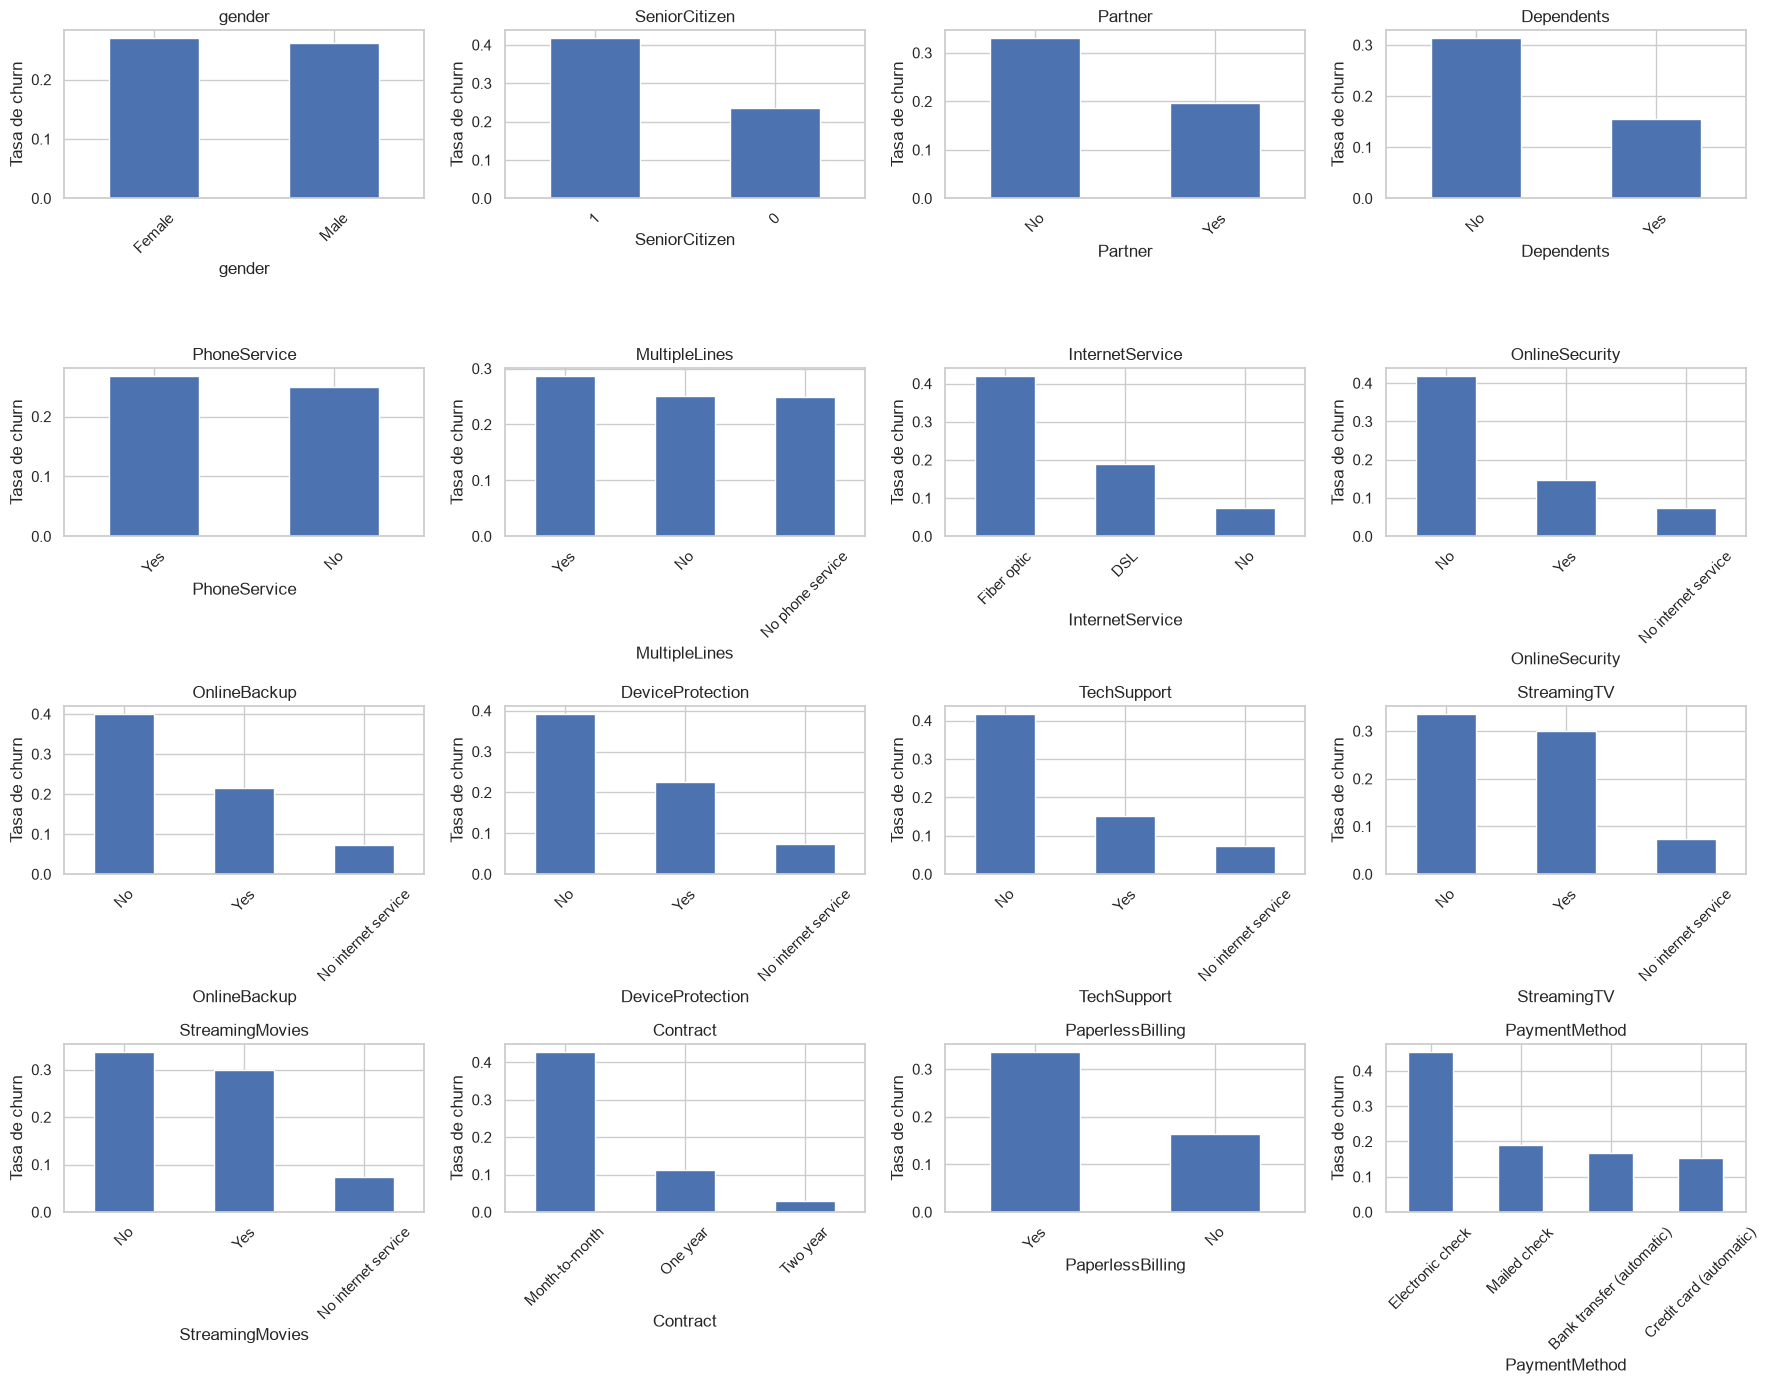

In [10]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flat, categorical_cols):
    churn_by_cat[col].plot(kind="bar", ax=ax, color="#4C72B0")
    ax.set_title(col)
    ax.set_ylabel("Tasa de churn")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## Correlación entre variables numéricas

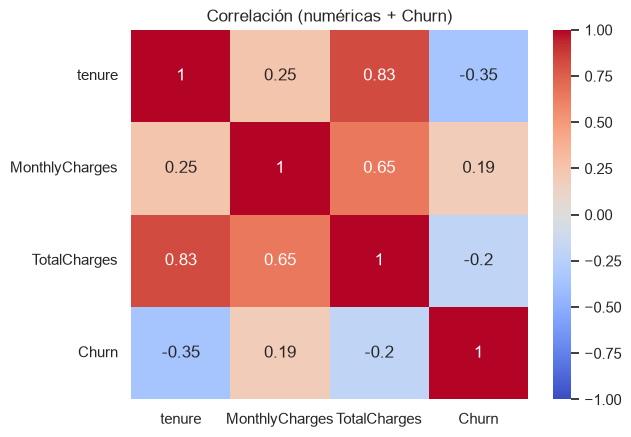

In [11]:
corr = df[numeric_cols + ["Churn"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación (numéricas + Churn)")
plt.show()